# 02 — Estatística do cold start

Este notebook responde, com estatística, às perguntas do estudo: **o cold start muda com runtime, memória, pacote, rede e cache?** e **o quanto?**

Ele lê os CSVs de `resultados/brutos/`, usa só as invocações **frias** (`tipo == "frio"`) para as métricas de cold start e segue o que está descrito no `analise/README.md`.

**Roteiro**

1. Configuração e leitura dos dados
2. Qualidade dos dados (o que entra na análise)
3. Distribuição: por que usar estatística não paramétrica
4. Resumo por configuração (mediana, p95, IC95% por bootstrap, overhead frio × quente)
5. Comparações entre configurações (Mann-Whitney + Holm, Kruskal-Wallis, tamanho de efeito)
6. Figuras dos experimentos E1 a E4
7. Fases do cold start
8. Diagnóstico: deriva, host e outliers
9. Exportação e principais achados

**Como rodar:** abra o notebook a partir da raiz do repositório ou da pasta `analise/`. Para analisar outra rodada, mude só `PADRAO` e `PREFIXO` na primeira célula.

## 1. Configuração e leitura dos dados

In [1]:
from pathlib import Path
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats
from IPython.display import display

PADRAO = "rodada1_*.csv"    
PREFIXO = "rodada1_nb"       
ALFA = 0.05                 
N_BOOT = 5000                
SEMENTE = 42                 

RAIZ = Path.cwd() if (Path.cwd() / "resultados").exists() else Path.cwd().parent
SAIDA = RAIZ / "analise" / "saida"
SAIDA.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(SEMENTE)

FATORES = ["workload", "runtime", "pacote", "mem_mib", "rede", "cache"]
CORES = {"python": "#4C6FE0", "nodejs": "#2DB84B"}  

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

In [25]:
arquivos = sorted((RAIZ / "resultados" / "brutos").glob(PADRAO))
assert arquivos, f"Nenhum arquivo encontrado para {PADRAO} em resultados/brutos/"

df = pd.concat([pd.read_csv(a).assign(arquivo=a.name) for a in arquivos], ignore_index=True)
print("Arquivos lidos:")
for a in arquivos:
    print("  -", a.name)
print(f"\n{len(df)} linhas, {df.config_id.nunique()} configurações, rodadas: {sorted(df.rodada.unique())}")

Arquivos lidos:
  - rodada1_2026-11-09_205908_principal.csv

2080 linhas, 26 configurações, rodadas: [np.int64(1)]


In [35]:
df['t_cold_total_ms'].median()

np.float64(754.545299)

## 2. Qualidade dos dados

Antes de qualquer teste, confira se há algo a descartar. O README lembra que amostras do backend `processo` (sem Docker) não entram nos resultados do estudo. Células vazias em métricas **não** viram zero: ficam como `NaN` e são ignoradas nas estatísticas.

In [ ]:
frio_bruto = df[df.tipo == "frio"]
quente_bruto = df[df.tipo == "quente"]
checagens = pd.Series({
    "linhas com validacao != ok":      int((df.validacao != "ok").sum()),
    "linhas com backend != docker":    int((df.backend != "docker").sum()),
    "frias com http_status != 200":    int((frio_bruto.http_status != 200).sum()),
    "frias com oom_kill > 0":          int((frio_bruto.oom_kill.fillna(0) > 0).sum()),
    "frias sem t_cold_total_ms":       int(frio_bruto.t_cold_total_ms.isna().sum()),
    "quentes com http_status != 200":    int((quente_bruto.http_status != 200).sum()),
    "quentes com oom_kill > 0":          int((quente_bruto.oom_kill.fillna(0) > 0).sum()),
    "quentes sem t_cold_total_ms":       int(quente_bruto.t_cold_total_ms.isna().sum()),
})
display(checagens.to_frame("ocorrências"))


n_por_cfg = df.pivot_table(index=["exp", "config_id"], columns="tipo", values="amostra_id", aggfunc="count")
display(n_por_cfg)

,ocorrências
linhas com validacao != ok,0
linhas com backend != docker,0
frias com http_status != 200,0
frias com oom_kill > 0,0
frias sem t_cold_total_ms,0
quentes com http_status != 200,0
quentes com oom_kill > 0,0
quentes sem t_cold_total_ms,1300


tipo                frio  quente
exp config_id                   
E1  E1-js-1024        30      50
    E1-js-128         30      50
    E1-js-256         30      50
    E1-js-512         30      50
    E1-py-1024        30      50
    E1-py-128         30      50
    E1-py-256         30      50
    E1-py-512         30      50
E2  E2-js-ampliado    30      50
    E2-js-minimo      30      50
    E2-js-padrao      30      50
    E2-py-ampliado    30      50
    E2-py-minimo      30      50
    E2-py-padrao      30      50
E3  E3-js-bridge      30      50
    E3-js-host        30      50
    E3-py-bridge      30      50
    E3-py-host        30      50
E4  E4-a1-js-aque     30      50
    E4-a1-js-desc     30      50
    E4-a1-py-aque     30      50
    E4-a1-py-desc     30      50
    E4-a2-js-aque     30      50
    E4-a2-js-desc     30      50
    E4-a2-py-aque     30      50
    E4-a2-py-desc     30      50

In [8]:
df = df[(df.validacao == "ok") & (df.backend == "docker")].copy()
frio = df[df.tipo == "frio"].copy()
quente = df[df.tipo == "quente"].copy()

frio["fase_criacao"]   = frio.t_created_ms
frio["fase_inicio"]    = frio.t_started_ms - frio.t_created_ms
frio["fase_prontidao"] = frio.t_ready_ms - frio.t_started_ms
frio["fase_espera"]    = frio.gap_ready_req_ms
frio["fase_req"]       = frio.t_req_cold_ms

quente["fase_criacao"]   = quente.t_created_ms
quente["fase_inicio"]    = quente.t_started_ms - quente.t_created_ms
quente["fase_prontidao"] = quente.t_ready_ms - quente.t_started_ms
quente["fase_espera"]    = quente.gap_ready_req_ms
quente["fase_req"]       = quente.t_req_cold_ms

fases_cols = ["fase_criacao", "fase_inicio", "fase_prontidao", "fase_espera", "fase_req"]

soma = frio[fases_cols].sum(axis=1)
print("Conferência: |soma das fases - t_cold_total| máximo =", float((soma - frio.t_cold_total_ms).abs().max()).__round__(6), "ms")
print(f"Frias: {len(frio)} | Quentes: {len(quente)} | menor n frio por configuração: {frio.groupby('config_id').size().min()}")

Conferência: |soma das fases - t_cold_total| máximo = 0.0 ms
Frias: 780 | Quentes: 1300 | menor n frio por configuração: 30


## 3. Distribuição dos tempos

Testes como o t de Student assumem dados aproximadamente normais. Tempos de latência costumam ser **assimétricos** (cauda longa para cima). Vamos medir isso: o teste de Shapiro-Wilk por configuração e a assimetria (skew). Se muitas configurações rejeitarem a normalidade, a escolha por **mediana** e por testes **não paramétricos** (Mann-Whitney, Kruskal-Wallis) fica justificada.

In [9]:
linhas = []
for cid, g in frio.groupby("config_id"):
    x = g.t_cold_total_ms.dropna()
    linhas.append({"config_id": cid, "n": len(x), "assimetria": stats.skew(x), "shapiro_p": stats.shapiro(x).pvalue})
norm = pd.DataFrame(linhas)

rejeitam = int((norm.shapiro_p < ALFA).sum())
print(f"{rejeitam} de {len(norm)} configurações rejeitam normalidade (Shapiro-Wilk, p < {ALFA}).")
print(f"Assimetria mediana: {norm.assimetria.median():.2f} (0 = simétrica; positivo = cauda para valores altos)")
display(norm.sort_values("shapiro_p").head(8).round(4))

17 de 26 configurações rejeitam normalidade (Shapiro-Wilk, p < 0.05).
Assimetria mediana: 2.66 (0 = simétrica; positivo = cauda para valores altos)


,config_id,n,assimetria,shapiro_p
7,E1-py-512,30,5.1538,0.0
11,E2-py-ampliado,30,5.1140,0.0
23,E4-a2-js-desc,30,4.9126,0.0
9,E2-js-minimo,30,4.7180,0.0
10,E2-js-padrao,30,4.5166,0.0
17,E3-py-host,30,4.8880,0.0
16,E3-py-bridge,30,3.5248,0.0
22,E4-a2-js-aque,30,4.2993,0.0


## 4. Resumo por configuração

Para cada configuração, com as amostras frias:

- **mediana**, **IQR** (intervalo entre o 1º e o 3º quartil) e **p95**: medidas robustas a outliers;
- **IC95% da mediana** por bootstrap: reamostramos os dados com reposição `N_BOOT` vezes e pegamos os percentis 2,5% e 97,5% das medianas obtidas;
- **CV** (desvio padrão ÷ média): variabilidade relativa;
- **overhead** = mediana do cold start − mediana da latência quente (`lat_req_ms` nas invocações quentes).

O p99 é exploratório: com menos de 100 amostras por configuração, ele depende de 1 ou 2 pontos.

In [ ]:
def ic_bootstrap(x, nivel=0.95, n_boot=N_BOOT):
    x = np.asarray(x, dtype=float)
    idx = rng.integers(0, len(x), size=(n_boot, len(x)))
    medianas = np.median(x[idx], axis=1)
    return tuple(np.percentile(medianas, [(1 - nivel) / 2 * 100, (1 + nivel) / 2 * 100]))

quente_med = quente.groupby("config_id").lat_req_ms.median()

linhas = []
for (exp, cid), g in frio.groupby(["exp", "config_id"]):
    x = g.t_cold_total_ms.dropna()
    q1, q3 = x.quantile([0.25, 0.75])
    lo, hi = ic_bootstrap(x)
    linha = {"exp": exp, "config_id": cid, **{f: g[f].iloc[0] for f in FATORES}}
    linha.update({
        "n": len(x), "media": x.mean(), "mediana": x.median(), "dp": x.std(),
        "iqr": q3 - q1, "p95": x.quantile(0.95), "p99": x.quantile(0.99),
        "cv": x.std() / x.mean(), "ic95_lo": lo, "ic95_hi": hi,
        "quente_mediana": quente_med.get(cid, np.nan),
    })
    linhas.append(linha)
    
resumo = pd.DataFrame(linhas)
resumo["overhead_ms"] = resumo.mediana - resumo.quente_mediana
resumo["razao_frio_quente"] = resumo.mediana / resumo.quente_mediana
display(resumo.round(2))

,exp,config_id,workload,runtime,pacote,mem_mib,rede,cache,n,media,mediana,dp,iqr,p95,p99,cv,ic95_lo,ic95_hi,quente_mediana,overhead_ms,razao_frio_quente
0,E1,E1-js-1024,A1,nodejs,padrao,1024,bridge,aquecido,30,755.32,753.00,29.94,24.49,777.66,859.10,0.04,743.11,758.16,3.17,749.82,237.50
1,E1,E1-js-128,A1,nodejs,padrao,128,bridge,aquecido,30,741.53,742.28,9.98,13.00,755.19,759.26,0.01,737.07,747.15,3.33,738.95,222.58
2,E1,E1-js-256,A1,nodejs,padrao,256,bridge,aquecido,30,743.74,740.39,13.63,15.75,765.42,777.39,0.02,737.63,747.81,3.48,736.91,212.88
3,E1,E1-js-512,A1,nodejs,padrao,512,bridge,aquecido,30,746.72,738.67,30.78,21.93,805.13,852.31,0.04,733.49,746.04,3.47,735.21,213.15
4,E1,E1-py-1024,A1,python,padrao,1024,bridge,aquecido,30,778.38,779.70,8.86,10.87,792.32,795.25,0.01,774.69,781.17,2.82,776.89,276.73
5,E1,E1-py-128,A1,python,padrao,128,bridge,aquecido,30,781.86,782.63,9.91,10.35,796.77,804.22,0.01,779.51,784.61,2.97,779.66,263.22
6,E1,E1-py-256,A1,python,padrao,256,bridge,aquecido,30,780.55,780.72,10.74,13.26,790.96,810.59,0.01,776.07,784.32,2.86,777.86,273.06
7,E1,E1-py-512,A1,python,padrao,512,bridge,aquecido,30,806.12,778.76,145.17,13.23,810.62,1353.68,0.18,774.03,783.28,2.77,775.99,280.66
8,E2,E2-js-ampliado,A2,nodejs,ampliado,256,bridge,aquecido,30,749.02,748.73,11.60,13.32,770.06,779.68,0.02,744.40,752.32,82.97,665.76,9.02
9,E2,E2-js-minimo,A2,nodejs,minimo,256,bridge,aquecido,30,778.53,748.74,141.49,15.25,866.75,1337.67,0.18,742.78,755.96,84.96,663.78,8.81


## 5. Comparações entre configurações

Comparamos duas configurações **somente quando diferem em um único fator** (runtime, memória, pacote, rede ou cache) e têm o **mesmo workload**. Assim, qualquer diferença pode ser atribuída àquele fator. As comparações são feitas **dentro de cada experimento**.

Para cada par:

- **Mann-Whitney U** (bilateral): testa se um grupo tende a ter valores maiores que o outro, sem supor normalidade;
- **correção de Holm** por experimento: como fazemos vários testes, a chance de um falso positivo cresce; Holm controla isso (é mais poderosa que Bonferroni);
- **delta de Cliff**: tamanho do efeito, de −1 a +1. É a probabilidade de A ser maior que B menos a probabilidade de A ser menor que B. Positivo significa que **A é mais lento**. Convenção: |δ| < 0,147 desprezível, < 0,33 pequeno, < 0,474 médio, acima disso grande;
- **Kruskal-Wallis da família**: testa todos os níveis de um fator de uma vez (por exemplo, as 4 memórias do mesmo runtime), antes de olhar os pares.

Um p pequeno diz que a diferença provavelmente não é acaso; o delta diz se ela **importa**. Com muitas amostras, diferenças minúsculas ficam significativas, então olhe os dois.

In [11]:
def holm(p):
    p = np.asarray(p, dtype=float)
    m = len(p)
    ordem = np.argsort(p)
    ajustado = np.empty(m)
    maximo = 0.0
    for posicao, i in enumerate(ordem):
        maximo = max(maximo, (m - posicao) * p[i])
        ajustado[i] = min(1.0, maximo)
    return ajustado

def classificar_efeito(d):
    d = abs(d)
    if d < 0.147: return "desprezível"
    if d < 0.33:  return "pequeno"
    if d < 0.474: return "médio"
    return "grande"

cfg = frio.groupby("config_id")[["exp"] + FATORES].first()
FATORES_TESTADOS = [f for f in FATORES if f != "workload"]   # o workload é mantido fixo nos pares

linhas = []
for exp, cfgs in cfg.groupby("exp"):
    for fator in FATORES_TESTADOS:
        outros = [f for f in FATORES if f != fator]
        # família = configurações iguais em todos os fatores, exceto `fator`
        for _, familia in cfgs.groupby(outros):
            ids = list(familia.index)
            if len(ids) < 2:
                continue
            amostras = {i: frio.loc[frio.config_id == i, "t_cold_total_ms"].dropna().values for i in ids}
            kw_p = stats.kruskal(*amostras.values()).pvalue
            for a, b in itertools.combinations(ids, 2):
                xa, xb = amostras[a], amostras[b]
                u, p = stats.mannwhitneyu(xa, xb, alternative="two-sided")
                delta = 2 * u / (len(xa) * len(xb)) - 1      # delta de Cliff (A vs B)
                ma, mb = np.median(xa), np.median(xb)
                linhas.append({
                    "exp": exp, "fator": fator, "config_a": a, "config_b": b,
                    "nivel_a": familia.loc[a, fator], "nivel_b": familia.loc[b, fator],
                    "mediana_a": ma, "mediana_b": mb, "dif_ms": ma - mb, "dif_pct": (ma / mb - 1) * 100,
                    "U": u, "p": p, "cliff_delta": delta, "efeito": classificar_efeito(delta),
                    "kruskal_p_familia": kw_p,
                })

comp = pd.DataFrame(linhas)
comp["p_holm"] = comp.groupby("exp")["p"].transform(lambda s: pd.Series(holm(s.values), index=s.index))
comp["signif"] = comp.p_holm < ALFA
print(f"{len(comp)} comparações; {int(comp.signif.sum())} significativas após Holm (alfa = {ALFA}).")

37 comparações; 19 significativas após Holm (alfa = 0.05).


In [12]:
cols = ["exp", "fator", "nivel_a", "nivel_b", "config_a", "config_b", "mediana_a", "mediana_b",
        "dif_ms", "dif_pct", "cliff_delta", "efeito", "p", "p_holm", "signif"]
mostrar = comp[cols].copy()
mostrar["abs_delta"] = mostrar.cliff_delta.abs()
mostrar = mostrar.sort_values(["exp", "abs_delta"], ascending=[True, False]).drop(columns="abs_delta")
display(mostrar.round({"mediana_a": 1, "mediana_b": 1, "dif_ms": 1, "dif_pct": 1, "cliff_delta": 2, "p": 4, "p_holm": 4}))

,exp,fator,nivel_a,nivel_b,config_a,config_b,mediana_a,mediana_b,dif_ms,dif_pct,cliff_delta,efeito,p,p_holm,signif
0,E1,runtime,nodejs,python,E1-js-128,E1-py-128,742.3,782.6,-40.4,-5.2,-1.00,grande,0.0000,0.0000,True
1,E1,runtime,nodejs,python,E1-js-256,E1-py-256,740.4,780.7,-40.3,-5.2,-0.96,grande,0.0000,0.0000,True
2,E1,runtime,nodejs,python,E1-js-512,E1-py-512,738.7,778.8,-40.1,-5.1,-0.85,grande,0.0000,0.0000,True
3,E1,runtime,nodejs,python,E1-js-1024,E1-py-1024,753.0,779.7,-26.7,-3.4,-0.83,grande,0.0000,0.0000,True
4,E1,mem_mib,1024,128,E1-js-1024,E1-js-128,753.0,742.3,10.7,1.4,0.36,médio,0.0176,0.2118,False
6,E1,mem_mib,1024,512,E1-js-1024,E1-js-512,753.0,738.7,14.3,1.9,0.32,pequeno,0.0339,0.3726,False
5,E1,mem_mib,1024,256,E1-js-1024,E1-js-256,753.0,740.4,12.6,1.7,0.29,pequeno,0.0537,0.5369,False
10,E1,mem_mib,1024,128,E1-py-1024,E1-py-128,779.7,782.6,-2.9,-0.4,-0.22,pequeno,0.1413,1.0000,False
14,E1,mem_mib,128,512,E1-py-128,E1-py-512,782.6,778.8,3.9,0.5,0.16,pequeno,0.2905,1.0000,False
13,E1,mem_mib,128,256,E1-py-128,E1-py-256,782.6,780.7,1.9,0.2,0.12,desprezível,0.4376,1.0000,False


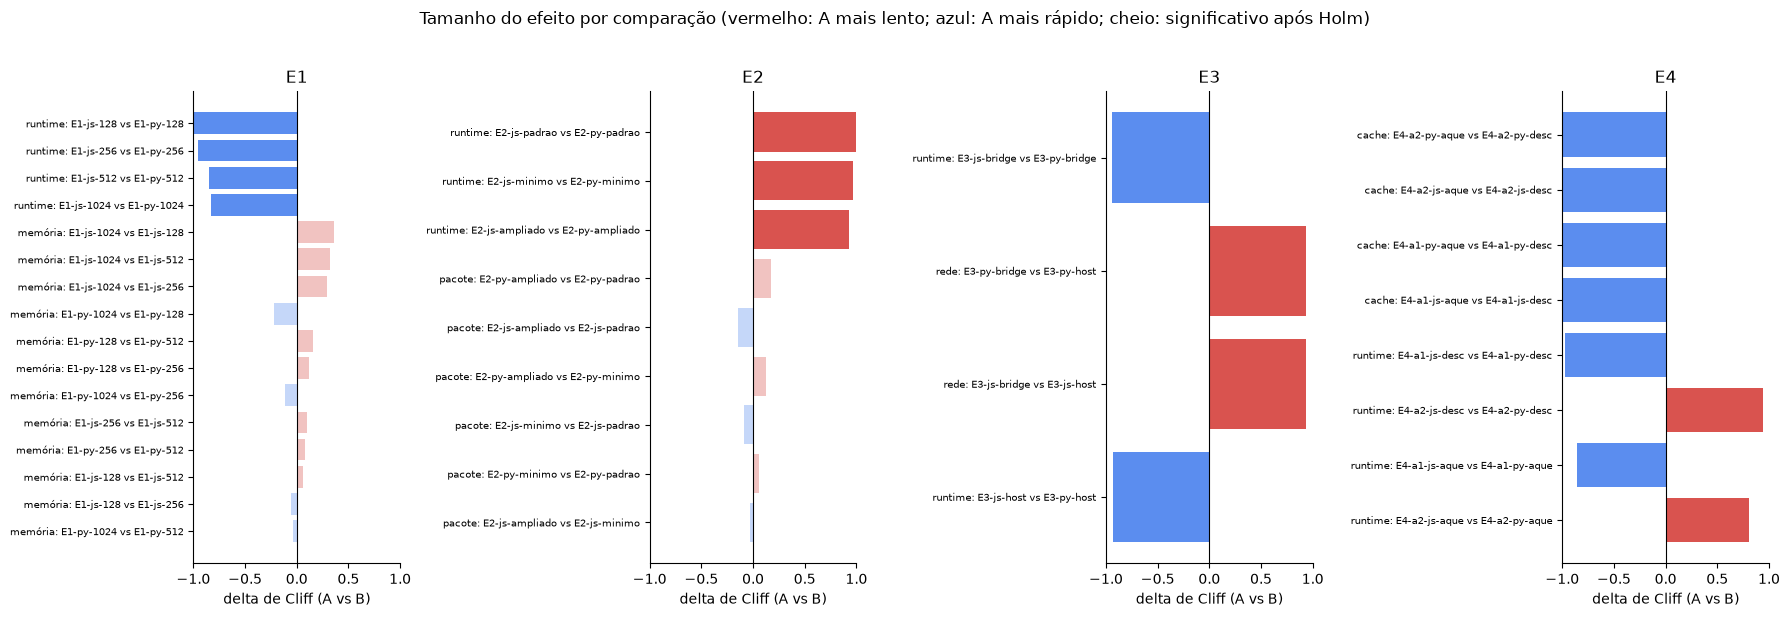

In [13]:
# Resumo visual dos efeitos: cada barra é um par; barras cheias = significativo após Holm
fig, axes = plt.subplots(1, 4, figsize=(18, 6), sharex=True)
for ax, (exp, g) in zip(axes, comp.groupby("exp")):
    g = g.assign(rotulo=g.fator.str.replace("mem_mib", "memória") + ": " + g.config_a + " vs " + g.config_b)
    g = g.reindex(g.cliff_delta.abs().sort_values().index)
    y = np.arange(len(g))
    cores = np.where(g.cliff_delta > 0, "#d9534f", "#5b8def")
    barras = ax.barh(y, g.cliff_delta, color=cores)
    for barra, significativo in zip(barras, g.signif):
        barra.set_alpha(1.0 if significativo else 0.35)
    ax.set_yticks(y); ax.set_yticklabels(g.rotulo, fontsize=7)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(exp); ax.set_xlim(-1, 1)
    ax.set_xlabel("delta de Cliff (A vs B)")
fig.suptitle("Tamanho do efeito por comparação (vermelho: A mais lento; azul: A mais rápido; cheio: significativo após Holm)", y=1.02)
fig.tight_layout()
fig.savefig(SAIDA / f"fig_{PREFIXO}_efeitos.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Figuras dos experimentos

Cada caixa mostra a mediana (linha preta), o IQR (caixa) e os pontos individuais (com um pequeno deslocamento horizontal para não sobrepor). Ver os pontos é importante: a caixa sozinha esconde o número de amostras e os outliers.

In [14]:
def caixas(ax, d, x_col, ordem_x):
    larg = 0.32
    for j, rt in enumerate(["nodejs", "python"]):
        for i, nivel in enumerate(ordem_x):
            v = d.loc[(d.runtime == rt) & (d[x_col] == nivel), "t_cold_total_ms"].dropna().values
            if len(v) == 0:
                continue
            pos = i + (j - 0.5) * (larg + 0.04)
            bp = ax.boxplot([v], positions=[pos], widths=larg, patch_artist=True,
                            showfliers=False, medianprops=dict(color="black", lw=1.5))
            bp["boxes"][0].set(facecolor=CORES[rt], alpha=0.45, edgecolor=CORES[rt])
            ax.scatter(pos + rng.uniform(-larg / 3, larg / 3, len(v)), v, s=8, color=CORES[rt], alpha=0.7, zorder=3)
    ax.set_xticks(range(len(ordem_x)))
    ax.set_xticklabels([str(o) for o in ordem_x])
    ax.set_xlim(-0.6, len(ordem_x) - 0.4)
    ax.set_xlabel(x_col)
    ax.set_ylabel("T_cold_total (ms)")
    ax.grid(axis="y", alpha=0.3)

def legenda(ax):
    ax.legend(handles=[Patch(color=CORES[r], alpha=0.6, label=r) for r in ["nodejs", "python"]], title="runtime", frameon=False)

def salvar(fig, nome):
    fig.savefig(SAIDA / f"fig_{PREFIXO}_{nome}.png", dpi=150, bbox_inches="tight")
    plt.show()

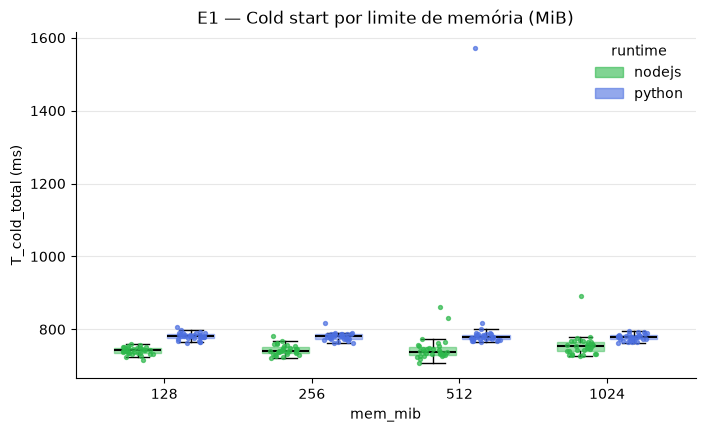

In [ ]:
d = frio[frio.exp == "E1"]
fig, ax = plt.subplots(figsize=(8, 4.5))
caixas(ax, d, "mem_mib", sorted(d.mem_mib.unique()))
ax.set_title("E1 — Cold start por limite de memória (MiB)")
legenda(ax);

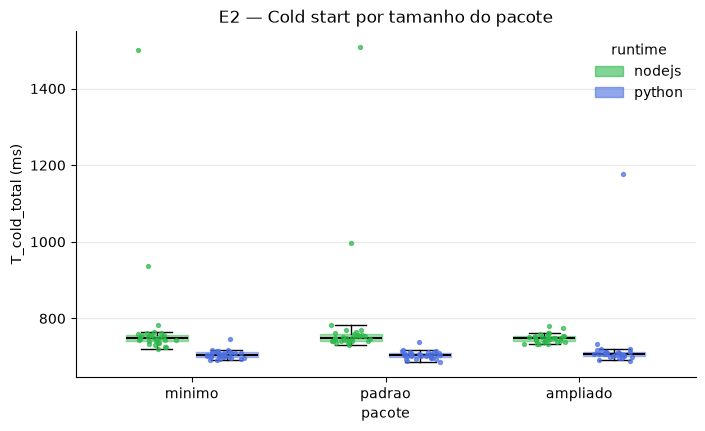

In [ ]:

d = frio[frio.exp == "E2"]
ordem = [p for p in ["minimo", "padrao", "ampliado"] if p in d.pacote.unique()]
fig, ax = plt.subplots(figsize=(8, 4.5))
caixas(ax, d, "pacote", ordem)
ax.set_title("E2 — Cold start por tamanho do pacote")
legenda(ax);

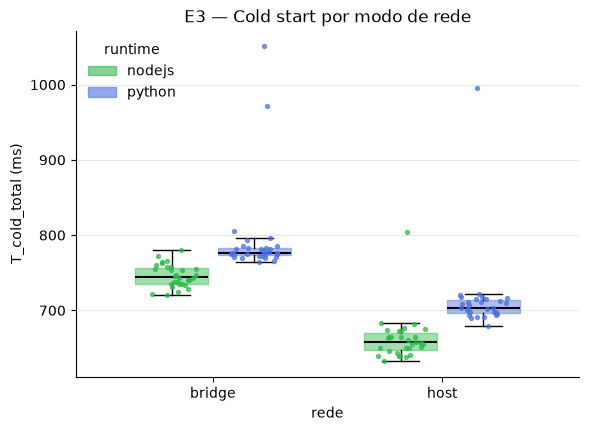

In [ ]:
d = frio[frio.exp == "E3"]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
caixas(ax, d, "rede", ["bridge", "host"])
ax.set_title("E3 — Cold start por modo de rede")
legenda(ax);

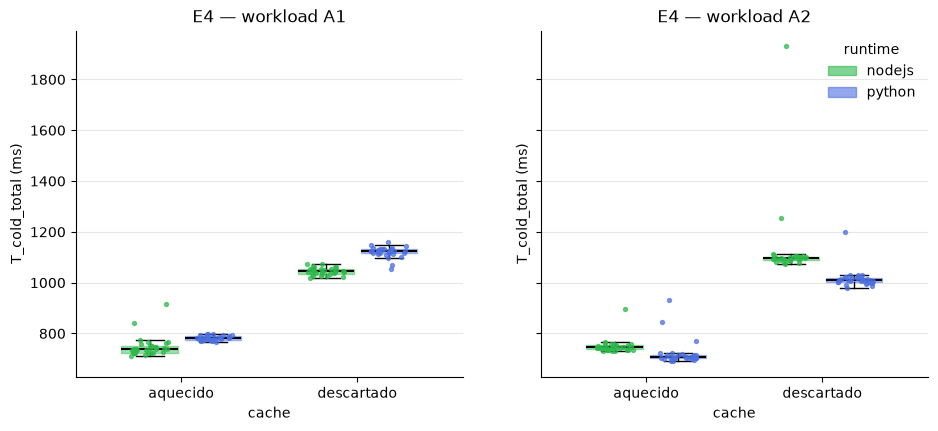

In [ ]:
d = frio[frio.exp == "E4"]
workloads = sorted(d.workload.unique())
fig, axes = plt.subplots(1, len(workloads), figsize=(5.5 * len(workloads), 4.5), sharey=True)
axes = np.atleast_1d(axes)
for ax, w in zip(axes, workloads):
    caixas(ax, d[d.workload == w], "cache", ["aquecido", "descartado"])
    ax.set_title(f"E4 — workload {w}")
legenda(axes[-1]);

## 7. Fases do cold start

Onde o tempo é gasto? Dividimos o cold start em cinco fases (calculadas a partir dos marcos acumulados):

| Fase | Como é calculada |
|---|---|
| criação | `t_created_ms` |
| início | `t_started_ms − t_created_ms` |
| prontidão | `t_ready_ms − t_started_ms` |
| espera até a 1ª requisição | `gap_ready_req_ms` |
| 1ª requisição | `t_req_cold_ms` |

**Cuidado de leitura:** o total de cada barra é a **soma das medianas das fases**, que não é igual à mediana do total. E só o `T_cold_total` é comparável entre runtimes: o Node carrega a função ao subir (o custo cai na prontidão), enquanto o Python carrega na 1ª requisição (o custo cai na fase da requisição).

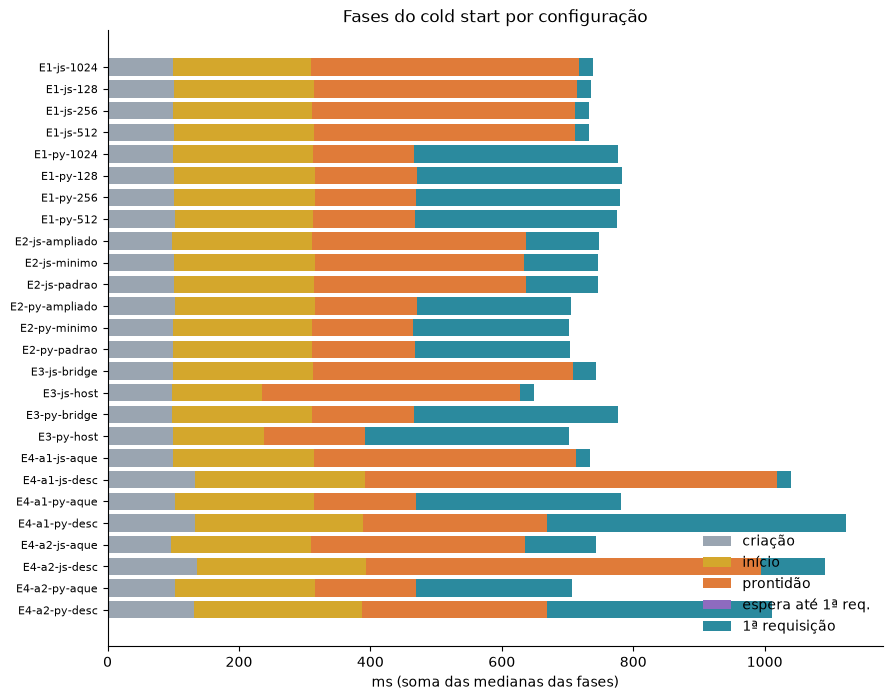

,srv_import_ms,t_cold_total_ms
runtime,,
nodejs,16.0,747.1
python,300.6,774.6


In [19]:
nomes = {"fase_criacao": "criação", "fase_inicio": "início", "fase_prontidao": "prontidão",
         "fase_espera": "espera até 1ª req.", "fase_req": "1ª requisição"}
med_fases = frio.groupby(["exp", "config_id"])[fases_cols].median().rename(columns=nomes)
med_fases = med_fases.sort_index(ascending=False)

paleta = ["#9aa5b1", "#d4a72c", "#e07b39", "#8e6bbf", "#2b8a9e"]
fig, ax = plt.subplots(figsize=(10, 8))
esquerda = np.zeros(len(med_fases))
for cor, col in zip(paleta, med_fases.columns):
    ax.barh(range(len(med_fases)), med_fases[col], left=esquerda, color=cor, label=col)
    esquerda += med_fases[col].values
ax.set_yticks(range(len(med_fases)))
ax.set_yticklabels([c for _, c in med_fases.index], fontsize=8)
ax.set_xlabel("ms (soma das medianas das fases)")
ax.set_title("Fases do cold start por configuração")
ax.legend(frameon=False, loc="lower right")
salvar(fig, "fases")

display(frio.groupby("runtime")[["srv_import_ms", "t_cold_total_ms"]].median().round(1))

## 8. Diagnóstico: deriva, host e outliers

Um experimento só é confiável se o ambiente ficou estável. Três verificações:

1. **Deriva:** os tempos mudam ao longo da rodada (aquecimento do host, throttling)? Dividimos cada tempo pela mediana da sua configuração (`rel`, 1,0 = típico) e olhamos contra `ordem` (a ordem de execução).
2. **Host:** temperatura, frequência, memória e swap antes de cada amostra. Algum deles se associa a tempos mais altos?
3. **Outliers:** quantas amostras ficam muito acima da mediana da própria configuração?

4 de 26 configurações com correlação ordem × tempo significativa (p < 0.05).
Ao acaso, esperaríamos cerca de 1.3. Bem acima disso indica deriva.


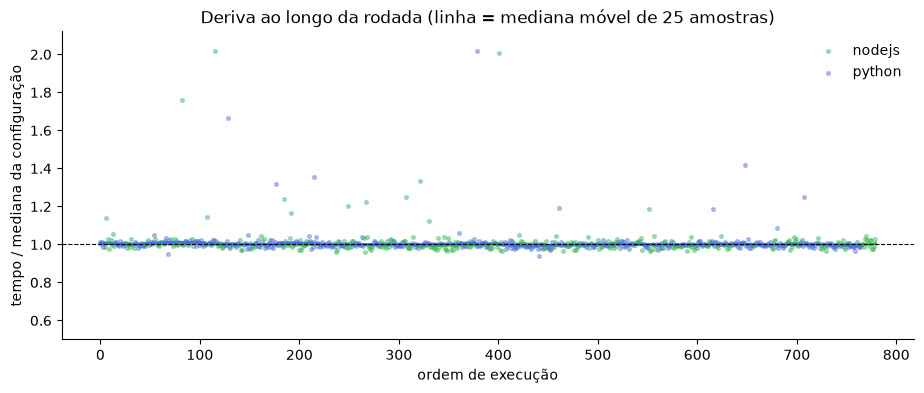

In [20]:
frio["rel"] = frio.t_cold_total_ms / frio.groupby("config_id").t_cold_total_ms.transform("median")

linhas = []
for cid, g in frio.groupby("config_id"):
    rho, p = stats.spearmanr(g.ordem, g.t_cold_total_ms)
    linhas.append({"config_id": cid, "rho": rho, "p": p})
deriva = pd.DataFrame(linhas)
sig = int((deriva.p < ALFA).sum())
print(f"{sig} de {len(deriva)} configurações com correlação ordem × tempo significativa (p < {ALFA}).")
print(f"Ao acaso, esperaríamos cerca de {ALFA * len(deriva):.1f}. Bem acima disso indica deriva.")

fig, ax = plt.subplots(figsize=(11, 4))
for rt, g in frio.groupby("runtime"):
    g = g.sort_values("ordem")
    ax.scatter(g.ordem, g.rel, s=7, alpha=0.4, color=CORES[rt], label=rt)
    ax.plot(g.ordem, g.rel.rolling(25, center=True, min_periods=5).median(), color=CORES[rt], lw=2)
ax.axhline(1, color="black", lw=0.8, ls="--")
ax.set_ylim(0.5, min(3, frio.rel.max() * 1.05))
ax.set_xlabel("ordem de execução"); ax.set_ylabel("tempo / mediana da configuração")
ax.set_title("Deriva ao longo da rodada (linha = mediana móvel de 25 amostras)")
ax.legend(frameon=False); salvar(fig, "deriva")

In [21]:
host_num = ["host_temp_c", "host_freq_khz", "host_mem_disponivel_kb", "host_swap_usado_kb"]
display(frio[host_num].describe().round(1))
for c in ["host_governador", "host_na_tomada"]:
    display(frio[c].value_counts(dropna=False).to_frame(c))

linhas = []
for c in host_num:
    s = frio[[c, "rel"]].dropna()
    if s[c].nunique() > 1:
        rho, p = stats.spearmanr(s[c], s.rel)
        linhas.append({"variável do host": c, "rho (com tempo relativo)": rho, "p": p})
    else:
        linhas.append({"variável do host": c, "rho (com tempo relativo)": np.nan, "p": np.nan})
display(pd.DataFrame(linhas).round(4))

,host_temp_c,host_freq_khz,host_mem_disponivel_kb,host_swap_usado_kb
count,780.0,780.0,780.0,780.0
mean,61.1,2744988.2,4500045.1,0.0
std,2.4,324844.3,50837.6,0.0
min,53.8,2023015.2,4352900.0,0.0
25%,59.5,2508336.2,4470542.0,0.0
50%,60.9,2679696.6,4512652.0,0.0
75%,63.0,2930744.9,4538845.0,0.0
max,66.6,4042175.8,4592336.0,0.0


,host_governador
host_governador,
performance,780


,host_na_tomada
host_na_tomada,
True,780


,variável do host,rho (com tempo relativo),p
0,host_temp_c,-0.0798,0.0258
1,host_freq_khz,-0.0088,0.8065
2,host_mem_disponivel_kb,0.0470,0.1894
3,host_swap_usado_kb,NaN,NaN


In [ ]:
frio["outlier"] = frio.rel > 1.5
tab = frio.groupby(["exp", "runtime"]).outlier.agg(["sum", "count"]).rename(columns={"sum": "outliers", "count": "n"})
tab["%"] = (tab.outliers / tab.n * 100).round(1)
display(tab)

outliers    n    %
exp runtime                    
E1  nodejs          0  120  0.0
    python          1  120  0.8
E2  nodejs          2   90  2.2
    python          1   90  1.1
E3  nodejs          0   60  0.0
    python          0   60  0.0
E4  nodejs          1  120  0.8
    python          0  120  0.0

## 9. Exportação e principais achados

Os resultados são salvos em `analise/saida/` com o prefixo definido no início, para o Power BI ler (`Obter dados > Texto/CSV`).

In [23]:
resumo.to_csv(SAIDA / f"resumo_{PREFIXO}.csv", index=False)
comp.to_csv(SAIDA / f"comparacoes_{PREFIXO}.csv", index=False)
print("Gerados em", SAIDA)
for f in sorted(SAIDA.glob(f"*{PREFIXO}*")):
    print("  -", f.name)

Gerados em c:\Users\odilo\Documents\projetos\cold-start-so\analise\saida
  - comparacoes_rodada1_nb.csv
  - fig_rodada1_nb_deriva.png
  - fig_rodada1_nb_e1_memoria.png
  - fig_rodada1_nb_e2_pacote.png
  - fig_rodada1_nb_e3_rede.png
  - fig_rodada1_nb_e4_cache.png
  - fig_rodada1_nb_efeitos.png
  - fig_rodada1_nb_fases.png
  - resumo_rodada1_nb.csv


In [24]:
print("=== Comparações significativas após Holm (ordenadas pelo tamanho do efeito) ===\n")
achados = comp[comp.signif].copy()
achados["abs_delta"] = achados.cliff_delta.abs()
for _, r in achados.sort_values("abs_delta", ascending=False).iterrows():
    mais_lento, mais_rapido = (r.config_a, r.config_b) if r.dif_ms > 0 else (r.config_b, r.config_a)
    print(f"[{r.exp}] {r.fator}: {mais_lento} é mais lento que {mais_rapido} "
          f"em {abs(r.dif_ms):.0f} ms ({abs(r.dif_pct):.0f}%) | efeito {r.efeito} (delta = {r.cliff_delta:+.2f}), p_holm = {r.p_holm:.4f}")

nao = comp[~comp.signif]
print(f"\n{len(nao)} comparações sem diferença significativa após Holm.")

=== Comparações significativas após Holm (ordenadas pelo tamanho do efeito) ===

[E1] runtime: E1-py-128 é mais lento que E1-js-128 em 40 ms (5%) | efeito grande (delta = -1.00), p_holm = 0.0000
[E4] cache: E4-a1-py-desc é mais lento que E4-a1-py-aque em 342 ms (30%) | efeito grande (delta = -1.00), p_holm = 0.0000
[E4] cache: E4-a1-js-desc é mais lento que E4-a1-js-aque em 307 ms (29%) | efeito grande (delta = -1.00), p_holm = 0.0000
[E4] cache: E4-a2-js-desc é mais lento que E4-a2-js-aque em 349 ms (32%) | efeito grande (delta = -1.00), p_holm = 0.0000
[E4] cache: E4-a2-py-desc é mais lento que E4-a2-py-aque em 302 ms (30%) | efeito grande (delta = -1.00), p_holm = 0.0000
[E2] runtime: E2-js-padrao é mais lento que E2-py-padrao em 44 ms (6%) | efeito grande (delta = +0.99), p_holm = 0.0000
[E4] runtime: E4-a1-py-desc é mais lento que E4-a1-js-desc em 77 ms (7%) | efeito grande (delta = -0.98), p_holm = 0.0000
[E2] runtime: E2-js-minimo é mais lento que E2-py-minimo em 44 ms (6%) | ef

### Como interpretar e relatar

- Fale em **mediana e intervalo** (IC95% ou IQR), não só em média.
- Uma diferença é relevante quando é **significativa (p_holm) e o efeito não é desprezível**. Diga os dois.
- Ausência de significância **não prova** que não há diferença; com n pequeno, o teste pode não ter poder para detectá-la.
- Registre limitações: tempos de uma única máquina, um único backend (Docker) e o que o diagnóstico da seção 8 mostrou sobre deriva e host.